# Задача 2: Извлечение корня из комплексного числа

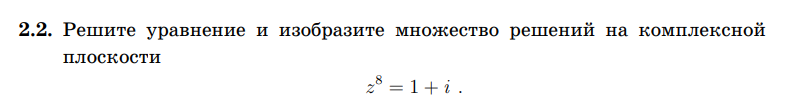

## Математическая база

### Корни n-й степени из комплексного числа

Пусть дано уравнение $z^n = w$, где $w$ — комплексное число. Тогда это уравнение имеет ровно $n$ различных корней в комплексной плоскости.

**Теорема.** Если комплексное число $w$ записано в тригонометрической форме:
$$w = R(\cos\psi + i\sin\psi), \quad R = |w|, \quad \psi = \arg(w)$$

то все $n$ корней уравнения $z^n = w$ вычисляются по формуле:

$$\boxed{z_k = \sqrt[n]{R} \left( \cos\frac{\psi + 2\pi k}{n} + i\sin\frac{\psi + 2\pi k}{n} \right), \quad k = 0, 1, 2, \ldots, n-1}$$

### Геометрическая интерпретация

Все $n$ корней лежат на **окружности** радиуса $\sqrt[n]{R}$ с центром в начале координат и образуют вершины **правильного $n$-угольника**. Угловое расстояние между соседними корнями равно $\dfrac{2\pi}{n}$.

### Формула Эйлера (показательная форма корней)

$$z_k = \sqrt[n]{R} \cdot e^{\,i\,\frac{\psi + 2\pi k}{n}}, \quad k = 0, 1, \ldots, n-1$$


k=0: z_0 = 1.039245 + 0.102357i
     Модуль: 1.044274, Аргумент: 5.625°
k=1: z_1 = 0.662480 + 0.807235i
     Модуль: 1.044274, Аргумент: 50.625°
k=2: z_2 = -0.102357 + 1.039245i
     Модуль: 1.044274, Аргумент: 95.625°
k=3: z_3 = -0.807235 + 0.662480i
     Модуль: 1.044274, Аргумент: 140.625°
k=4: z_4 = -1.039245 + -0.102357i
     Модуль: 1.044274, Аргумент: 185.625°
k=5: z_5 = -0.662480 + -0.807235i
     Модуль: 1.044274, Аргумент: 230.625°
k=6: z_6 = 0.102357 + -1.039245i
     Модуль: 1.044274, Аргумент: 275.625°
k=7: z_7 = 0.807235 + -0.662480i
     Модуль: 1.044274, Аргумент: 320.625°


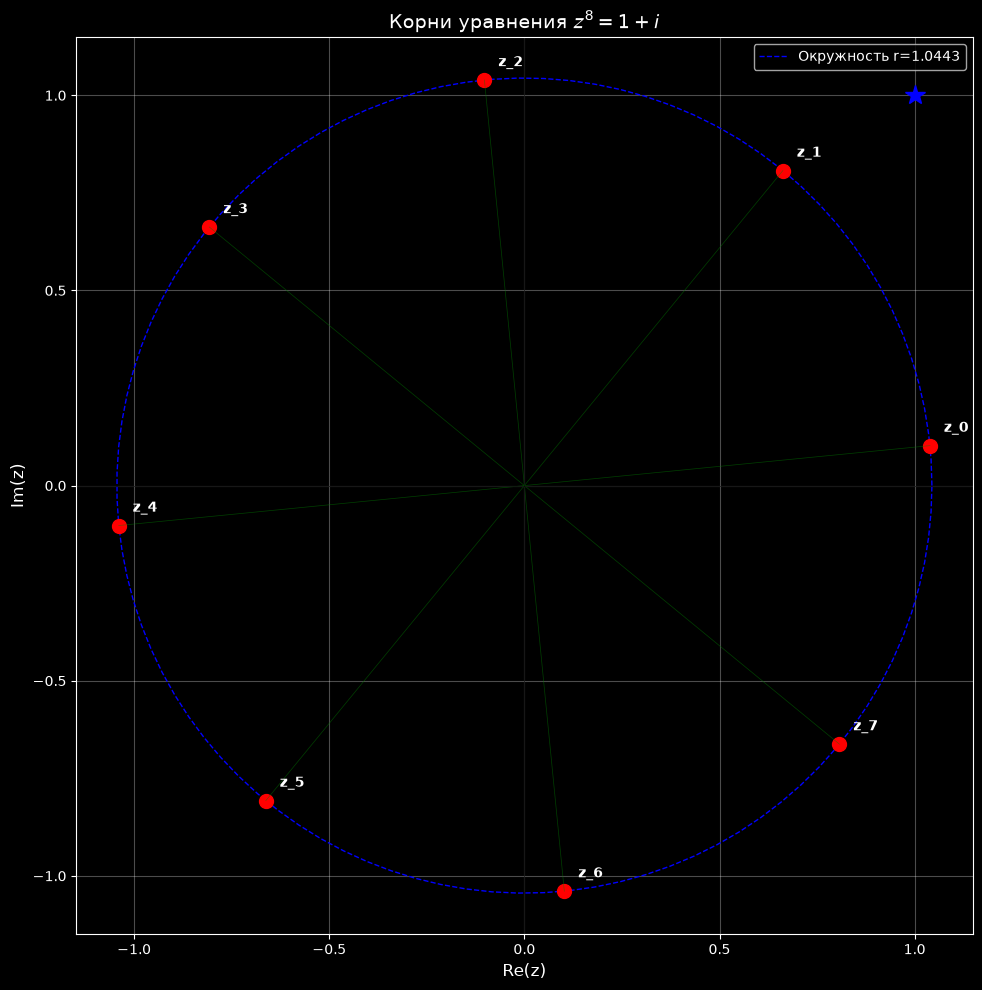


Все корни лежат на окружности радиуса R = 2^(1/16) ≈ 1.044274
Угловое расстояние между корнями: 45.0°


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cmath

# Параметры уравнения z^8 = 1 + i
n = 8
w = 1 + 1j
r = abs(w)
phi = cmath.phase(w)

# Модуль корней
R = r ** (1/n)

# Вычисляем все корни
roots = []
for k in range(n):
    angle = (phi + 2 * np.pi * k) / n
    z_k = R * np.exp(1j * angle)
    roots.append(z_k)
    print(f"k={k}: z_{k} = {z_k.real:.6f} + {z_k.imag:.6f}i")
    print(f"     Модуль: {abs(z_k):.6f}, Аргумент: {np.degrees(angle):.3f}°")

# Визуализация на комплексной плоскости
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Рисуем окружность радиуса R
theta = np.linspace(0, 2*np.pi, 100)
circle_x = R * np.cos(theta)
circle_y = R * np.sin(theta)
ax.plot(circle_x, circle_y, 'b--', linewidth=1, label=f'Окружность r={R:.4f}')

# Рисуем корни
for k, z in enumerate(roots):
    ax.plot(z.real, z.imag, 'ro', markersize=10)
    ax.annotate(f'z_{k}', (z.real, z.imag),
                textcoords="offset points", xytext=(10, 10),
                fontsize=10, fontweight='bold')
    # Линии от центра к корням
    ax.plot([0, z.real], [0, z.imag], 'g-', linewidth=0.5, alpha=0.5)

# Оси координат
ax.axhline(y=0, color='k', linewidth=0.5)
ax.axvline(x=0, color='k', linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.set_xlabel('Re(z)', fontsize=12)
ax.set_ylabel('Im(z)', fontsize=12)
ax.set_title('Корни уравнения $z^8 = 1+i$', fontsize=14)
ax.legend()
ax.set_aspect('equal')

# Добавляем точку w = 1+i для справки
ax.plot(1, 1, 'b*', markersize=15, label='w = 1+i')

plt.tight_layout()
plt.savefig('roots_z8.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nВсе корни лежат на окружности радиуса R = 2^(1/16) ≈ {R:.6f}")
print(f"Угловое расстояние между корнями: {360/n}°")